# Tokyo Bay & Ise Bay — Data Processing

**Objective**: Load raw environmental data (Shapefiles) for Tokyo Bay and Ise Bay, clean/process it, and save to merged Feather files for analysis.

**Adapted from**: `notebooks/pipeline/01_Data_Processing.ipynb`

In [3]:
import sys
from pathlib import Path

# Ensure local scripts are importable (notebook is in notebooks/pipeline/)
project_root = Path("../").resolve()
sys.path.append(str(project_root))

from scripts.data_loader import load_and_process_data
from scripts.paths import ProjectPaths
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import cartopy.feature as cfeature

print("Project Root:", project_root)

Project Root: /home/reyha/SIS_Analysis_WSL


In [4]:
# Force reload to include the newly added Tokyo Bay & Ise Bay data
merged_gdf = load_and_process_data(force_reload=True)

print("Data Shape:", merged_gdf.shape)
merged_gdf.info()

Loading raw shapefiles from 1981 to 2023...
Merging 182 shapefiles...
Processing data (cleaning DO, adding seasons)...
Saving processed data to /home/reyha/SIS_Analysis_WSL/data/processed/merged_gdf.feather...
Data Shape: (65643, 65)
<class 'geopandas.geodataframe.GeoDataFrame'>
RangeIndex: 65643 entries, 0 to 65642
Data columns (total 65 columns):
 #   Column          Non-Null Count  Dtype         
---  ------          --------------  -----         
 0   uniqueid        65643 non-null  object        
 1   zettaicode      65643 non-null  object        
 2   locationna      65643 non-null  object        
 3   wancode         65643 non-null  object        
 4   prefectuei      65643 non-null  object        
 5   watercode       65643 non-null  int64         
 6   renban          65643 non-null  object        
 7   nendo           65643 non-null  int64         
 8   survey_ym       65643 non-null  datetime64[ms]
 9   surveyyear      65643 non-null  int64         
 10  surveymont      6564

In [5]:
# --- Inspect available water mass names to find Tokyo/Ise Bay entries ---
print("Unique watermass_name values:")
print(merged_gdf['watermass_name'].unique())
print("\nUnique division values:")
print(merged_gdf['division'].unique())


Unique watermass_name values:
['Ise Bay' 'Seto Inland Sea' 'Tokyo Bay' nan]

Unique division values:
['—' 'Osaka Bay' 'Kii Channel' 'Harima Nada' 'Iyo Nada' 'Suo Nada'
 'Bisan Seto' 'Bungo Channel' 'Bingo Nada' 'Hibiki Nada' 'Aki Nada'
 'Hiuchi Nada' 'Hiroshima Bay' nan]


In [6]:
# --- Filter for Tokyo Bay ---
# ADJUST the filter condition below to match your actual data labels
tokyo_bay_gdf = merged_gdf[
    merged_gdf['watermass_name'].str.contains('Tokyo', case=False, na=False) |
    merged_gdf['division'].str.contains('Tokyo', case=False, na=False)
].copy()

print(f"Tokyo Bay data shape: {tokyo_bay_gdf.shape}")

# --- Filter for Ise Bay ---
# ADJUST the filter condition below to match your actual data labels
ise_bay_gdf = merged_gdf[
    merged_gdf['watermass_name'].str.contains('Ise', case=False, na=False) |
    merged_gdf['division'].str.contains('Ise', case=False, na=False)
].copy()

print(f"Ise Bay data shape: {ise_bay_gdf.shape}")

Tokyo Bay data shape: (9145, 65)
Ise Bay data shape: (8362, 65)


In [7]:
for label, df_inspect in [("Tokyo Bay", tokyo_bay_gdf), ("Ise Bay", ise_bay_gdf)]:
    print(f"\n{'='*60}")
    print(f"=== {label} ===")
    print(f"{'='*60}")

    print(f"Shape: {df_inspect.shape}")

    # --- Data Info ---
    print("\n--- Data Info ---")
    df_inspect.info()

    print("\n--- First 5 Rows ---")
    display(df_inspect.head())

    print("\n--- Last 5 Rows ---")
    display(df_inspect.tail())

    # --- Missing Values ---
    missing_count = df_inspect.isnull().sum()
    missing_percent = (missing_count / len(df_inspect)) * 100
    missing_df = pd.DataFrame({
        'Missing Values': missing_count,
        'Percentage': missing_percent
    }).sort_values(by='Missing Values', ascending=False)
    print("\n--- Columns with Missing Data ---")
    display(missing_df[missing_df['Missing Values'] > 0])

    # --- Numeric Statistics ---
    df_numeric = df_inspect.copy()
    for col in ['temp', 'wtemp', 'salt', 'do_']:
        if col in df_numeric.columns:
            df_numeric[col] = pd.to_numeric(df_numeric[col], errors='coerce')
    print("\n--- Statistics for Numeric Columns ---")
    display(df_numeric.describe().T)


=== Tokyo Bay ===
Shape: (9145, 65)

--- Data Info ---
<class 'geopandas.geodataframe.GeoDataFrame'>
Index: 9145 entries, 1208 to 65378
Data columns (total 65 columns):
 #   Column          Non-Null Count  Dtype         
---  ------          --------------  -----         
 0   uniqueid        9145 non-null   object        
 1   zettaicode      9145 non-null   object        
 2   locationna      9145 non-null   object        
 3   wancode         9145 non-null   object        
 4   prefectuei      9145 non-null   object        
 5   watercode       9145 non-null   int64         
 6   renban          9145 non-null   object        
 7   nendo           9145 non-null   int64         
 8   survey_ym       9145 non-null   datetime64[ms]
 9   surveyyear      9145 non-null   int64         
 10  surveymont      9145 non-null   int64         
 11  surveyday       9145 non-null   int64         
 12  surveyhour      9145 non-null   int64         
 13  surveymini      9145 non-null   int64        

,uniqueid,zettaicode,locationna,wancode,prefectuei,watercode,renban,nendo,survey_ym,surveyyear,...,doc,doc2,dataflag,scale,geometry,year,watermass_name,division,details,season
1208,0000001196,00000124,千葉県4,01,12,100,4,1981,1981-12-01,1982,...,0.8,0.8,1,-1,POINT (140.06083 35.605),1981,Tokyo Bay,—,—,Winter
1209,0000001197,00000124,千葉県4,01,12,100,4,1981,1981-03-01,1981,...,None,0.0,1,-1,POINT (140.06083 35.605),1981,Tokyo Bay,—,—,Spring
1210,0000001198,00000124,千葉県4,01,12,100,4,1981,1981-06-01,1981,...,None,0.0,1,-1,POINT (140.06083 35.605),1981,Tokyo Bay,—,—,Summer
1211,0000001199,00000124,千葉県4,01,12,100,4,1981,1981-09-01,1981,...,None,0.0,1,-1,POINT (140.06083 35.605),1981,Tokyo Bay,—,—,Autumn
1212,0000001200,00000124,千葉県4,01,12,100,4,1981,1981-12-01,1982,...,None,0.0,1,-1,POINT (140.06083 35.605),1981,Tokyo Bay,—,—,Winter



--- Last 5 Rows ---


,uniqueid,zettaicode,locationna,wancode,prefectuei,watercode,renban,nendo,survey_ym,surveyyear,...,doc,doc2,dataflag,scale,geometry,year,watermass_name,division,details,season
65374,0000067691,00001439,神奈川県39,01,14,100,39,2023,2023-12-01,2024,...,1.0,1.0,1,-1,POINT (139.75778 35.28556),2023,Tokyo Bay,—,—,Winter
65375,0000067692,00001441,神奈川県41,01,14,100,41,2023,2023-12-01,2024,...,1.3,1.3,1,-1,POINT (139.72167 35.35056),2023,Tokyo Bay,—,—,Winter
65376,0000067693,00001441,神奈川県41,01,14,100,41,2023,2023-12-01,2024,...,1.2,1.2,1,-1,POINT (139.72167 35.35056),2023,Tokyo Bay,—,—,Winter
65377,0000067694,00001446,神奈川県46,01,14,100,46,2023,2023-12-01,2024,...,1.1,1.1,1,-1,POINT (139.76333 35.22778),2023,Tokyo Bay,—,—,Winter
65378,0000067695,00001446,神奈川県46,01,14,100,46,2023,2023-12-01,2024,...,1.0,1.0,1,-1,POINT (139.76333 35.22778),2023,Tokyo Bay,—,—,Winter



--- Columns with Missing Data ---


...

,uniqueid,zettaicode,locationna,wancode,prefectuei,watercode,renban,nendo,survey_ym,surveyyear,...,doc,doc2,dataflag,scale,geometry,year,watermass_name,division,details,season
45543,0000047078,00002312,愛知県12,02,23,200,12,2012,2012-12-01,2013,...,None,0.0,1,-1,POINT (136.75861 34.90333),2012,Ise Bay,—,—,Winter
45544,0000047061,00002355,愛知県55,02,23,200,55,2012,2012-09-01,2012,...,1.8,1.8,1,-1,POINT (137.28028 34.79833),2012,Ise Bay,—,—,Autumn
45545,0000047075,00002310,愛知県10,02,23,200,10,2012,2012-12-01,2013,...,1.2,1.2,1,-1,POINT (136.80194 34.93667),2012,Ise Bay,—,—,Winter
45546,0000047005,00002361,愛知県61,02,23,200,61,2012,2012-03-01,2012,...,1.4,1.4,1,-1,POINT (137.28861 34.75333),2012,Ise Bay,—,—,Spring
45547,0000047160,00002439,三重県39,02,24,200,39,2012,2012-12-01,2013,...,None,0.0,1,-1,POINT (136.73028 34.55444),2012,Ise Bay,—,—,Winter



--- Columns with Missing Data ---


,Missing Values,Percentage
doc,4065,48.612772
rcod,4063,48.588854
clearness,3461,41.389620
toc,3118,37.287730
fuko,2876,34.393686
color,2775,33.185841
salt,2114,25.281033
fusoku,1604,19.182014
cloud,1242,14.852906
temp,1165,13.932074



--- Statistics for Numeric Columns ---


,count,mean,min,25%,50%,75%,max,std
watercode,8362.0,200.0,200.0,200.0,200.0,200.0,200.0,0.0
nendo,8362.0,1996.347525,1981.0,1988.0,1996.0,2004.0,2012.0,9.146393
survey_ym,8362,1996-11-20 18:04:33.810000,1981-03-01 00:00:00,1988-12-01 00:00:00,1996-12-01 00:00:00,2004-12-01 00:00:00,2012-12-01 00:00:00,NaN
surveyyear,8362.0,1996.600096,1981.0,1989.0,1997.0,2005.0,2013.0,9.160914
surveymont,8362.0,5.745755,1.0,2.0,5.0,8.0,10.0,3.258241
surveyday,8362.0,18.851471,3.0,16.0,19.0,22.0,30.0,4.916155
surveyhour,8362.0,9.033126,0.0,8.0,9.0,11.0,16.0,2.27958
surveymini,8362.0,28.389261,0.0,14.0,30.0,43.0,59.0,17.372523
saisuipoin,8362.0,1.5,1.0,1.0,1.5,2.0,2.0,0.50003
latitude,8362.0,34.752848,34.554444,34.67,34.75,34.83,34.99,0.120686


In [8]:
# Save each bay's processed data as separate feather files
tokyo_bay_path = ProjectPaths.PROCESSED_DATA_DIR / "tokyo_bay_gdf.feather"
ise_bay_path = ProjectPaths.PROCESSED_DATA_DIR / "ise_bay_gdf.feather"

tokyo_bay_gdf.to_feather(tokyo_bay_path)
print(f"Saved Tokyo Bay data to {tokyo_bay_path}")

ise_bay_gdf.to_feather(ise_bay_path)
print(f"Saved Ise Bay data to {ise_bay_path}")

Saved Tokyo Bay data to /home/reyha/SIS_Analysis_WSL/data/processed/tokyo_bay_gdf.feather
Saved Ise Bay data to /home/reyha/SIS_Analysis_WSL/data/processed/ise_bay_gdf.feather


## Sampling Point Maps

Visualize all sampling points for each bay. Following the SIS Mapping Standard but using **Cartopy `cfeature.LAND`** for landmass rendering instead of the SIS prefecture boundary shapefile (which does not cover the Tokyo Bay / Ise Bay region).

In [9]:
def plot_sampling_points(data_gdf, title, save_path=None):
    """
    Plot sampling point locations on a Cartopy map.

    Follows SIS Mapping Standard:
    - PlateCarree projection
    - Ocean background via set_facecolor
    - Cartopy LAND + COASTLINE for landmasses (10m resolution)
    - Dynamic extent with 0.2° buffer
    - Gridlines with standard formatting
    """
    fig, ax = plt.subplots(figsize=(10, 8), subplot_kw={'projection': ccrs.PlateCarree()})

    # --- Ocean background ---
    ax.set_facecolor('lightblue')

    # --- Cartopy landmasses (high-res, replacing SIS boundary) ---
    ax.add_feature(cfeature.LAND.with_scale('10m'), facecolor='#f0e6d2', zorder=1)
    ax.add_feature(cfeature.COASTLINE.with_scale('10m'), linewidth=0.8,
                   edgecolor='black', zorder=1.5)

    # --- Plot sampling points ---
    # Get unique station locations (drop duplicate lat/lon across years)
    stations = data_gdf.drop_duplicates(subset=['latitude', 'longitude'])
    stations.plot(
        ax=ax,
        markersize=15,
        color='red',
        edgecolor='black',
        linewidth=0.3,
        alpha=0.8,
        transform=ccrs.PlateCarree(),
        zorder=5
    )

    # --- Dynamic extent with 0.2° buffer ---
    bounds = data_gdf.total_bounds  # [minx, miny, maxx, maxy]
    ax.set_extent([
        bounds[0] - 0.2,  # xmin
        bounds[2] + 0.2,  # xmax
        bounds[1] - 0.2,  # ymin
        bounds[3] + 0.2   # ymax
    ], crs=ccrs.PlateCarree())

    # --- Gridlines ---
    gl = ax.gridlines(draw_labels=True, linestyle='--',
                      color='gray', alpha=0.5, linewidth=0.5, zorder=2)
    gl.top_labels = False
    gl.right_labels = False

    # --- Title ---
    ax.set_title(title, fontsize=14, fontweight='bold', pad=12)

    # --- Station count annotation ---
    n_stations = len(stations)
    n_records = len(data_gdf)
    ax.text(0.02, 0.02,
            f"Stations: {n_stations}\nRecords: {n_records}",
            transform=ax.transAxes,
            fontsize=9,
            verticalalignment='bottom',
            bbox=dict(boxstyle='round,pad=0.3', facecolor='white', alpha=0.8),
            zorder=10)

    plt.tight_layout()

    if save_path:
        fig.savefig(save_path, dpi=150, bbox_inches='tight')
        print(f"Saved figure to {save_path}")

    plt.show()

Saved figure to /home/reyha/SIS_Analysis_WSL/figures/tokyo_bay_sampling_points.png


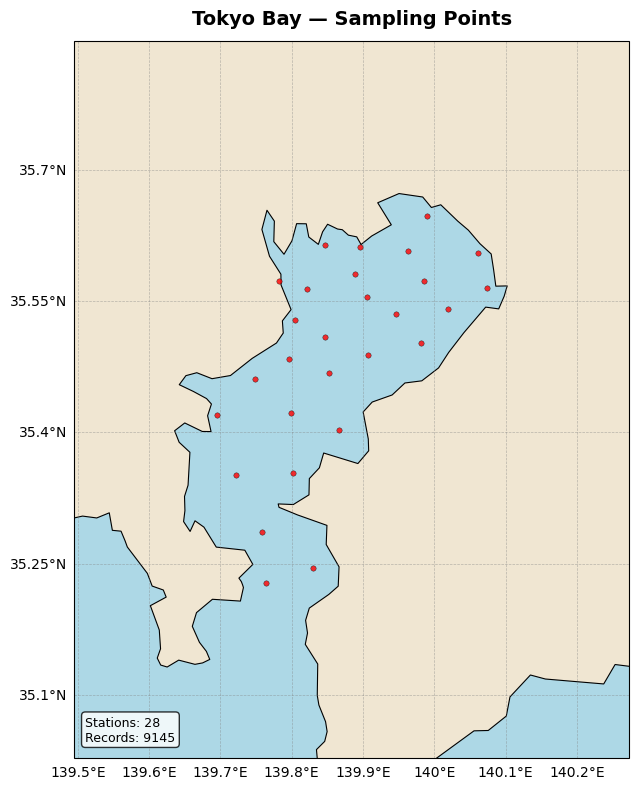

In [10]:
plot_sampling_points(
    tokyo_bay_gdf,
    title="Tokyo Bay — Sampling Points",
    save_path=ProjectPaths.FIGURES_DIR / "tokyo_bay_sampling_points.png"
)


Saved figure to /home/reyha/SIS_Analysis_WSL/figures/ise_bay_sampling_points.png


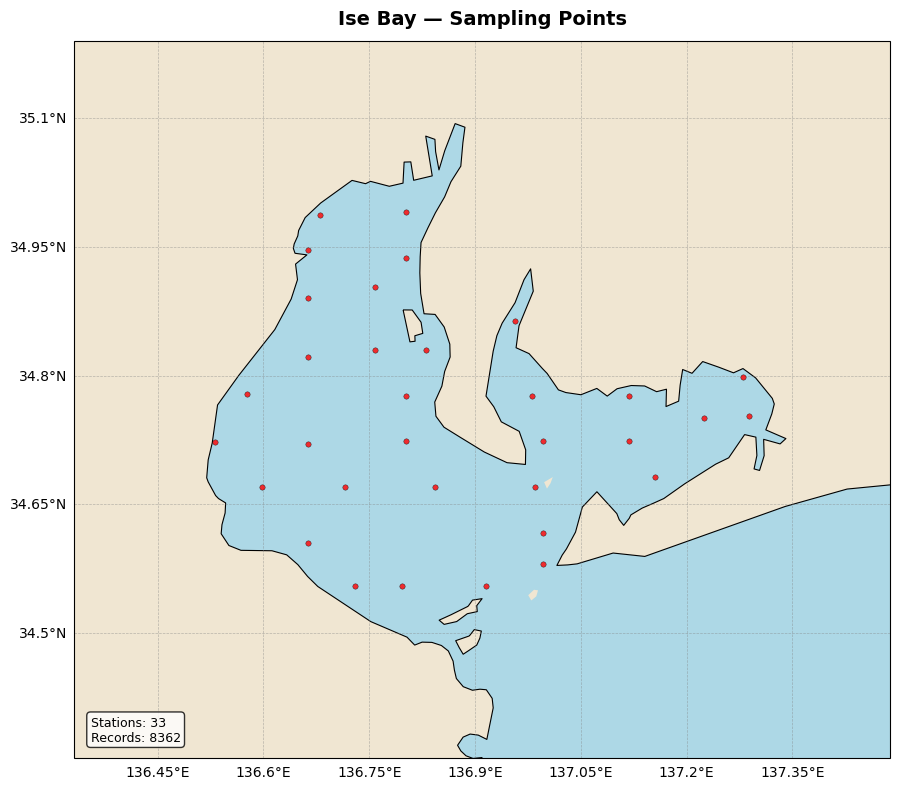

In [11]:
plot_sampling_points(
    ise_bay_gdf,
    title="Ise Bay — Sampling Points",
    save_path=ProjectPaths.FIGURES_DIR / "ise_bay_sampling_points.png"
)